In [1]:
# Q1: Install libraries and read the first page.
# A PDF cannot be used directly as text. We use PyPDF2 to open the file and extract_text() to get the text of a page, in the same way as in the Pollution PDF notebook.
!pip install PyPDF2 nltk spacy
!python -m spacy download en_core_web_sm

from PyPDF2 import PdfReader
reader=PdfReader("Biodiversity.pdf")
print("Number of pages:",len(reader.pages))
page=reader.pages[0]
print(page.extract_text())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 47.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Number of pages: 5
BIODIVERSITY    PAGE 1
 BIODIVERSITY
 The Variety of Life and Why It Matters
 
Meaning of Biodiversity
Biodiversity is the variety of living organisms found on Earth. It includes the diversity of plants, animals, fungi,
and microorganisms, as well as the genetic differences within species and the ecosystems in which they live.
Biodiversity exists in forests, grasslands, deserts, rivers, oceans, wetlands, and even in places shaped by
human activity.
Three Levels of Biodiversity
Biodiversity is commonly described at three connected levels. Genetic diversity r

In [2]:
# Q2: Read all pages and a specific page.
# enumerate(reader.pages,start=1) gives each page with its page number. A single page can be read by its index (page 3 has index 2 because counting starts from 0). Only the first 200 characters of each page are printed to keep the output short.
for page_number,page in enumerate(reader.pages,start=1):
    print(f"\n--- Page {page_number} ---")
    print(page.extract_text()[:200])

print("\n--- Page 3 (full) ---")
print(reader.pages[2].extract_text())


--- Page 1 ---
BIODIVERSITY    PAGE 1
 BIODIVERSITY
 The Variety of Life and Why It Matters
 
Meaning of Biodiversity
Biodiversity is the variety of living organisms found on Earth. It includes the diversity of pla

--- Page 2 ---
BIODIVERSITY    PAGE 2
 ECOSYSTEMS AND HABITATS
 How Species Depend on Their Surroundings
 
What Is an Ecosystem?
An ecosystem includes living organisms and the non-living parts of their environment 

--- Page 3 ---
BIODIVERSITY    PAGE 3
 THREATS TO BIODIVERSITY
 Human Pressures and Environmental Change
 
Habitat Loss and Fragmentation
Habitat loss occurs when natural areas are cleared or substantially altered.

--- Page 4 ---
BIODIVERSITY    PAGE 4
 CONSERVATION OF BIODIVERSITY
 Protecting Species, Habitats, and Natural Processes
 
Protected Areas
National parks, wildlife sanctuaries, marine protected areas, and other con

--- Page 5 ---
BIODIVERSITY    PAGE 5
 BIODIVERSITY IN DAILY LIFE
 Practical Action and a Shared Responsibility
 
What Individuals

In [3]:
# Q3: Search for a word in the PDF.
# We check every page and compare in lowercase so that "Ecosystem" and "ecosystem" are both found.
search_word="pollution"
for page_number,page in enumerate(reader.pages,start=1):
    page_text=page.extract_text()
    if search_word.lower() in page_text.lower():
        print(f"'{search_word}' found on page {page_number}")

'pollution' found on page 2
'pollution' found on page 3
'pollution' found on page 4
'pollution' found on page 5


In [4]:
# Q4: Count words in the PDF.
# We split the text of every page with split() and add the counts. The total is printed once, after the loop.
word_count=0
for page in reader.pages:
    page_text=page.extract_text()
    if page_text:
        word_count+=len(page_text.split())
print("Total words:",word_count)

Total words: 1013


In [5]:
# Q5: Copy the first page into another PDF.
# PdfWriter creates a new PDF. We add the first page of the original PDF to it and save it as first_page.pdf.
from PyPDF2 import PdfWriter

writer=PdfWriter()
writer.add_page(reader.pages[0])
with open("first_page.pdf","wb") as output:
    writer.write(output)
print("First page copied successfully!")

First page copied successfully!


In [6]:
# Q6: Save the PDF text into a text file.
# The text of every page is written into Biodiversity_text.txt with a page heading, so the PDF content can be reused as a normal text file.
with open("Biodiversity_text.txt","w",encoding="utf-8") as file:
    for page_number,page in enumerate(reader.pages,start=1):
        file.write(f"\n--- Page {page_number} ---\n")
        file.write(page.extract_text() or "")
print("PDF text saved successfully.")

PDF text saved successfully.


In [7]:
# Q7: Combine pages and clean the text.
# Every page starts with a header like "BIODIVERSITY - PAGE 1" which is not part of the real content. We remove it with re.sub, and replace line breaks and multiple spaces with a single space. The cleaned text is stored in text and is used in all the next questions.
import re

raw_text=""
for page in reader.pages:
    raw_text+=page.extract_text()+"\n"

text=re.sub(r"BIODIVERSITY[^\n]{0,10}PAGE \d+"," ",raw_text)
text=re.sub(r"\s+"," ",text).strip()

print("Characters before cleaning:",len(raw_text))
print("Characters after cleaning:",len(text))
print(text[:500])

Characters before cleaning: 7532
Characters after cleaning: 7386
BIODIVERSITY The Variety of Life and Why It Matters Meaning of Biodiversity Biodiversity is the variety of living organisms found on Earth. It includes the diversity of plants, animals, fungi, and microorganisms, as well as the genetic differences within species and the ecosystems in which they live. Biodiversity exists in forests, grasslands, deserts, rivers, oceans, wetlands, and even in places shaped by human activity. Three Levels of Biodiversity Biodiversity is commonly described at three c


In [8]:
# Q8: Sentence tokenization (NLTK).
# Sentence tokenization splits the full text into sentences. We use sent_tokenize from NLTK, as done in the NLTK tokenization notebook.
import nltk
from nltk.tokenize import sent_tokenize
nltk.download("punkt")
nltk.download("punkt_tab")

sentences=sent_tokenize(text)
print("Number of sentences:",len(sentences))
for i,sentence in enumerate(sentences[:5],start=1):
    print(f"\nSentence {i}:")
    print(sentence)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


Number of sentences: 60

Sentence 1:
BIODIVERSITY The Variety of Life and Why It Matters Meaning of Biodiversity Biodiversity is the variety of living organisms found on Earth.

Sentence 2:
It includes the diversity of plants, animals, fungi, and microorganisms, as well as the genetic differences within species and the ecosystems in which they live.

Sentence 3:
Biodiversity exists in forests, grasslands, deserts, rivers, oceans, wetlands, and even in places shaped by human activity.

Sentence 4:
Three Levels of Biodiversity Biodiversity is commonly described at three connected levels.

Sentence 5:
Genetic diversity refers to differences among individuals of the same species.


[nltk_data]   Package punkt_tab is already up-to-date!


In [9]:
# Q9: Word tokenization (NLTK).
# word_tokenize splits the text into words and punctuation marks. We then remove punctuation using string.punctuation and convert every word to lowercase so that "Biodiversity" and "biodiversity" are treated as the same word. The result is stored in words.
import string
from nltk.tokenize import word_tokenize

tokens=word_tokenize(text)
words=[token.lower() for token in tokens if token not in string.punctuation]

print("All tokens:",len(tokens))
print("Words without punctuation:",len(words))
print("Unique words:",len(set(words)))
print(words[:20])

All tokens: 1178
Words without punctuation: 995
Unique words: 464
['biodiversity', 'the', 'variety', 'of', 'life', 'and', 'why', 'it', 'matters', 'meaning', 'of', 'biodiversity', 'biodiversity', 'is', 'the', 'variety', 'of', 'living', 'organisms', 'found']


In [10]:
# Q10: Tokenization with spaCy.
# spaCy creates a doc object in which every token has properties like is_alpha and is_punct. The same doc will be reused later for stopwords, lemmatization and POS tagging.
import spacy
nlp=spacy.load("en_core_web_sm")
doc=nlp(text)

for token in doc[:15]:
    print(token.text,token.is_alpha,token.is_punct)

print("\nNumber of tokens:",len(doc))
print("Number of sentences:",len(list(doc.sents)))

BIODIVERSITY True False
The True False
Variety True False
of True False
Life True False
and True False
Why True False
It True False
Matters True False
Meaning True False
of True False
Biodiversity True False
Biodiversity True False
is True False
the True False

Number of tokens: 1196
Number of sentences: 62


In [11]:
# Q11: Stopword removal using spaCy.
# Stopwords are very common words like "the", "is", "and" that add little meaning. In spaCy every token has is_stop, so we keep only the tokens that are not stopwords and not punctuation.
spacy_words=[]
for token in doc:
    if not token.is_stop and not token.is_punct:
        spacy_words.append(token.text.lower())

print("Tokens before removal:",len(doc))
print("Words after removal:",len(spacy_words))
print(spacy_words[:20])

Tokens before removal: 1196
Words after removal: 669
['biodiversity', 'variety', 'life', 'matters', 'meaning', 'biodiversity', 'biodiversity', 'variety', 'living', 'organisms', 'found', 'earth', 'includes', 'diversity', 'plants', 'animals', 'fungi', 'microorganisms', 'genetic', 'differences']


In [12]:
# Q12: Stopword removal using NLTK.
# NLTK also has a list of English stopwords. We remove them from words (from Q9) and save the result in filtered_words, which will be used for stemming. Counter shows which important words appear most often in the Biodiversity PDF.
from nltk.corpus import stopwords
from collections import Counter
nltk.download("stopwords")

stop_words=set(stopwords.words("english"))
filtered_words=[word for word in words if word not in stop_words]

print("Words before removal:",len(words))
print("Words after removal:",len(filtered_words))
print("Stopwords removed:",len(words)-len(filtered_words))
print(Counter(filtered_words).most_common(10))

Words before removal: 995
Words after removal: 699
Stopwords removed: 296
[('species', 22), ('biodiversity', 17), ('habitats', 16), ('organisms', 10), ('ecosystems', 8), ('conservation', 8), ('reduce', 7), ('ecosystem', 6), ('food', 6), ('protecting', 6)]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [13]:
# Q13: Stemming using PorterStemmer.
# Stemming reduces a word to its root by cutting prefixes/suffixes, so the stem may not be a real word (for example, "species" and "ecosystems" may be changed in an odd way). We use PorterStemmer from NLTK.
from nltk.stem import PorterStemmer
stemmer=PorterStemmer()

for word in filtered_words[:15]:
    print(word,"->",stemmer.stem(word))

print()
for word in ["ecosystems","species","conservation","protecting","habitats","pollution"]:
    print(word,"->",stemmer.stem(word))

biodiversity -> biodivers
variety -> varieti
life -> life
matters -> matter
meaning -> mean
biodiversity -> biodivers
biodiversity -> biodivers
variety -> varieti
living -> live
organisms -> organ
found -> found
earth -> earth
includes -> includ
diversity -> divers
plants -> plant

ecosystems -> ecosystem
species -> speci
conservation -> conserv
protecting -> protect
habitats -> habitat
pollution -> pollut


In [14]:
# Q14: Lemmatization using spaCy.
# Lemmatization converts a word to its dictionary form (lemma), which is always a real word (for example, "ecosystems" becomes "ecosystem"). spaCy uses the POS of the word, so it gives better results than stemming.
for token in doc[:15]:
    if token.is_alpha:
        print(token.text,"POS:",token.pos_,"Lemma:",token.lemma_)

lemmatized_words=[]
for token in doc:
    if not token.is_stop and not token.is_punct:
        lemmatized_words.append(token.lemma_.lower())

print("\nLemmatized words:",len(lemmatized_words))
print(" ".join(lemmatized_words[:40]))

BIODIVERSITY POS: VERB Lemma: biodiversity
The POS: DET Lemma: the
Variety POS: PROPN Lemma: Variety
of POS: ADP Lemma: of
Life POS: PROPN Lemma: Life
and POS: CCONJ Lemma: and
Why POS: SCONJ Lemma: why
It POS: PRON Lemma: it
Matters POS: VERB Lemma: matter
Meaning POS: PROPN Lemma: Meaning
of POS: ADP Lemma: of
Biodiversity POS: PROPN Lemma: Biodiversity
Biodiversity POS: PROPN Lemma: Biodiversity
is POS: AUX Lemma: be
the POS: DET Lemma: the

Lemmatized words: 669
biodiversity variety life matter meaning biodiversity biodiversity variety living organism find earth include diversity plant animal fungus microorganism genetic difference specie ecosystem live biodiversity exist forest grassland desert river ocean wetland place shape human activity levels biodiversity biodiversity commonly describe


In [15]:
# Q15: Lemmatization using NLTK WordNet and comparison with stemming.
# WordNetLemmatizer needs the POS of the word (pos="n" for noun, pos="v" for verb). The table shows the difference: the stem may be cut incorrectly, while the lemma is a proper word.
import pandas as pd
from nltk.stem import WordNetLemmatizer
nltk.download("wordnet")
nltk.download("omw-1.4")
lemmatizer=WordNetLemmatizer()

for word in ["ecosystems","habitats","organisms","pollinators","species"]:
    print(word,"->",lemmatizer.lemmatize(word,pos="n"))

print()
for word in ["declines","depends","protecting","fragmented"]:
    print(word,"->",lemmatizer.lemmatize(word,pos="v"))

data=[]
for word in filtered_words[:15]:
    data.append({"Word":word,
                 "Stem":stemmer.stem(word),
                 "Lemma (noun)":lemmatizer.lemmatize(word,pos="n"),
                 "Lemma (verb)":lemmatizer.lemmatize(word,pos="v")})
df=pd.DataFrame(data)
print()
print(df)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


ecosystems -> ecosystem
habitats -> habitat
organisms -> organism
pollinators -> pollinator
species -> specie

declines -> decline
depends -> depend
protecting -> protect
fragmented -> fragment

            Word       Stem  Lemma (noun)  Lemma (verb)
0   biodiversity  biodivers  biodiversity  biodiversity
1        variety    varieti       variety       variety
2           life       life          life          life
3        matters     matter        matter        matter
4        meaning       mean       meaning          mean
5   biodiversity  biodivers  biodiversity  biodiversity
6   biodiversity  biodivers  biodiversity  biodiversity
7        variety    varieti       variety       variety
8         living       live        living          live
9      organisms      organ      organism     organisms
10         found      found         found          find
11         earth      earth         earth         earth
12      includes     includ      includes       include
13     diversity     

Nouns: 197 ['efforts', 'decomposers', 'laws', 'biodiversity', 'programmes', 'damage', 'activities', 'margins', 'waters', 'habitat', 'distance', 'wildlife', 'pollination', 'scale', 'populations']
Verbs: 115 ['means', 'biodiversity', 'conserving', 'put', 'introduced', 'avoid', 'controlling', 'avoiding', 'supports', 'find', 'observing', 'logged', 'include', 'protects', 'filter']
Adjectives: 67 ['human', 'extinct', 'situ', 'feasible', 'many', 'harder', 'unnecessary', 'intrinsic', 'adequate', 'important', 'serious', 'large', 'industrial', 'botanical', 'marine']
Counter({'NOUN': 353, 'PUNCT': 189, 'VERB': 156, 'ADJ': 101, 'CCONJ': 81, 'ADP': 76, 'PROPN': 72, 'DET': 45, 'AUX': 43, 'PRON': 27, 'ADV': 23, 'SCONJ': 17, 'PART': 10, 'NUM': 3})


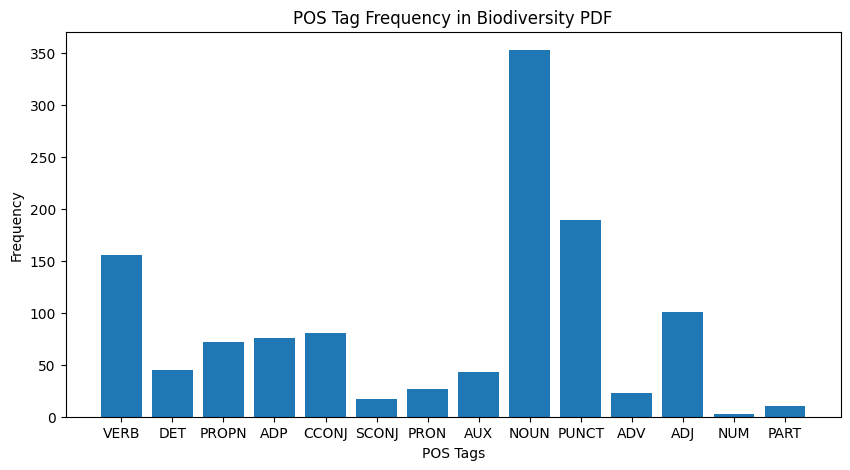

In [16]:
# Q16: POS tagging using spaCy.
# WordNetLemmatizer needs the POS of the word (pos="n" for noun, pos="v" for verb). The table shows the difference: the stem may be cut incorrectly, while the lemma is a proper word.
import matplotlib.pyplot as plt

nouns=set(token.text.lower() for token in doc if token.pos_=="NOUN")
verbs=set(token.text.lower() for token in doc if token.pos_=="VERB")
adjectives=set(token.text.lower() for token in doc if token.pos_=="ADJ")

print("Nouns:",len(nouns),list(nouns)[:15])
print("Verbs:",len(verbs),list(verbs)[:15])
print("Adjectives:",len(adjectives),list(adjectives)[:15])

pos_counts=Counter(token.pos_ for token in doc)
print(pos_counts)

plt.figure(figsize=(10,5))
plt.bar(pos_counts.keys(),pos_counts.values())
plt.xlabel("POS Tags")
plt.ylabel("Frequency")
plt.title("POS Tag Frequency in Biodiversity PDF")
plt.show()

In [17]:
# Q17: POS tagging using NLTK.
# NLTK uses pos_tag on tokenized words and gives Penn Treebank tags like NN (noun), VB (verb) and JJ (adjective). Tags starting with "NN" are nouns and tags starting with "JJ" are adjectives, as done in the NLTK POS tagging notebook.
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

for sentence in sentences[:3]:
    tags=nltk.pos_tag(word_tokenize(sentence))
    print("\nSentence:",sentence)
    print(tags)

all_tags=nltk.pos_tag(tokens)
nouns=[word for word,tag in all_tags if tag.startswith("NN")]
adjectives=[word for word,tag in all_tags if tag.startswith("JJ")]

print("\nTotal nouns:",len(nouns))
print("First 15 nouns:",nouns[:15])
print("First 15 adjectives:",adjectives[:15])
print(Counter(tag for word,tag in all_tags).most_common(10))

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...



Sentence: BIODIVERSITY The Variety of Life and Why It Matters Meaning of Biodiversity Biodiversity is the variety of living organisms found on Earth.
[('BIODIVERSITY', 'IN'), ('The', 'DT'), ('Variety', 'NNP'), ('of', 'IN'), ('Life', 'NNP'), ('and', 'CC'), ('Why', 'WRB'), ('It', 'PRP'), ('Matters', 'NNPS'), ('Meaning', 'NNP'), ('of', 'IN'), ('Biodiversity', 'NNP'), ('Biodiversity', 'NNP'), ('is', 'VBZ'), ('the', 'DT'), ('variety', 'NN'), ('of', 'IN'), ('living', 'NN'), ('organisms', 'NNS'), ('found', 'VBN'), ('on', 'IN'), ('Earth', 'NN'), ('.', '.')]

Sentence: It includes the diversity of plants, animals, fungi, and microorganisms, as well as the genetic differences within species and the ecosystems in which they live.
[('It', 'PRP'), ('includes', 'VBZ'), ('the', 'DT'), ('diversity', 'NN'), ('of', 'IN'), ('plants', 'NNS'), (',', ','), ('animals', 'NNS'), (',', ','), ('fungi', 'NNS'), (',', ','), ('and', 'CC'), ('microorganisms', 'RB'), (',', ','), ('as', 'RB'), ('well', 'RB'), ('as', 

[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
